# Training pipeline — Data loading checks

Before training, we check that FeTA and BOBs can be loaded correctly in PyTorch. We use the preprocessed MRI and mask files, and keep the training code in `src/`.

In [1]:

from pathlib import Path
import json

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
FETA_DIR = PROJECT_ROOT / "data" / "processed" / "feta_fomo"
BOBS_DIR = PROJECT_ROOT / "data" / "processed" / "bobs_fomo"

print("Project root:", PROJECT_ROOT)


Project root: c:\Users\yasmi\-brain-mri-foundation-models


## 1. Load the splits

FeTA has our own train/val/test split, balanced between MIAL and IRTK. For BOBs, we use the splits already provided. We check that no participant appears in two groups.

In [2]:

def load_splits(dataset):
    path = SPLITS_DIR / f"{dataset}_splits.json"
    with open(path, encoding="utf-8") as f:
        return json.load(f)

feta_splits = load_splits("feta")
bobs_splits = load_splits("bobs")

for name, splits in [("FeTA", feta_splits), ("BOBs", bobs_splits)]:
    print(f"\n{name}")
    for split, subjects in splits.items():
        print(f"  {split}: {len(subjects)} participants")

    all_ids = [subject for ids in splits.values() for subject in ids]
    assert len(all_ids) == len(set(all_ids)), "Participant overlap found!"

    print("  No participant overlap: OK")



FeTA
  train: 56 participants
  val: 12 participants
  test: 12 participants
  No participant overlap: OK

BOBs
  train: 20 participants
  val: 5 participants
  test_i: 8 participants
  test_ho: 18 participants
  No participant overlap: OK


## 2. Check the preprocessed files

We use the `.npy` files saved during preprocessing. The `.nii.gz` copies are kept for viewing and spatial checks.

In [3]:

for name, directory in [("FeTA", FETA_DIR), ("BOBs", BOBS_DIR)]:
    mri_files = sorted(directory.glob("sub-*/**/anat/*_T2w.npy"))
    print(f"{name}: {len(mri_files)} preprocessed MRI arrays")


FeTA: 80 preprocessed MRI arrays
BOBs: 71 preprocessed MRI arrays


## 3. Extract 3D patches

We try `BrainMRIPatchDataset` on both datasets. It loads an MRI and its mask, then takes a matching 96 × 96 × 96 patch. Smaller volumes are padded only where needed.

In [4]:

import sys
import torch

sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import BrainMRIPatchDataset

# Check one training patch from each dataset.
for name, directory in [("feta", FETA_DIR), ("bobs", BOBS_DIR)]:
    dataset = BrainMRIPatchDataset(
        data_dir=directory,
        splits_path=SPLITS_DIR / f"{name}_splits.json",
        dataset=name,
        split="train",
        patch_size=(96, 96, 96),
    )

    sample = dataset[0]

    print(f"\n{name.upper()}")
    print("Number of training MRI volumes:", len(dataset))
    print("MRI patch shape:", sample["image"].shape)
    print("Mask patch shape:", sample["mask"].shape)
    print("MRI dtype:", sample["image"].dtype)
    print("Mask dtype:", sample["mask"].dtype)
    print("Labels in patch:", torch.unique(sample["mask"]).tolist())
    print("Subject:", sample["subject"])



FETA
Number of training MRI volumes: 56
MRI patch shape: torch.Size([1, 96, 96, 96])
Mask patch shape: torch.Size([96, 96, 96])
MRI dtype: torch.float32
Mask dtype: torch.int64
Labels in patch: [0, 1, 2, 3, 4, 5, 6, 7]
Subject: sub-004

BOBS
Number of training MRI volumes: 29
MRI patch shape: torch.Size([1, 96, 96, 96])
Mask patch shape: torch.Size([96, 96, 96])
MRI dtype: torch.float32
Mask dtype: torch.int64
Labels in patch: [0, 1, 2, 3, 4, 5, 6, 7]
Subject: sub-116845


## 4. FeTA — Test a batch

The DataLoader groups patches into batches. Here we check the shapes of two FeTA MRI patches and their masks.

In [5]:

from torch.utils.data import DataLoader

train_dataset = BrainMRIPatchDataset(
    data_dir=FETA_DIR,
    splits_path=SPLITS_DIR / "feta_splits.json",
    dataset="feta",
    split="train",
    patch_size=(96, 96, 96),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
)

batch = next(iter(train_loader))

print("MRI batch:", batch["image"].shape)
print("Mask batch:", batch["mask"].shape)
print("Subjects:", batch["subject"])


MRI batch: torch.Size([2, 1, 96, 96, 96])
Mask batch: torch.Size([2, 96, 96, 96])
Subjects: ['sub-051', 'sub-036']


### FeTA — Visual check

We show one MRI patch with its segmentation to see if the labels line up with the brain structures.

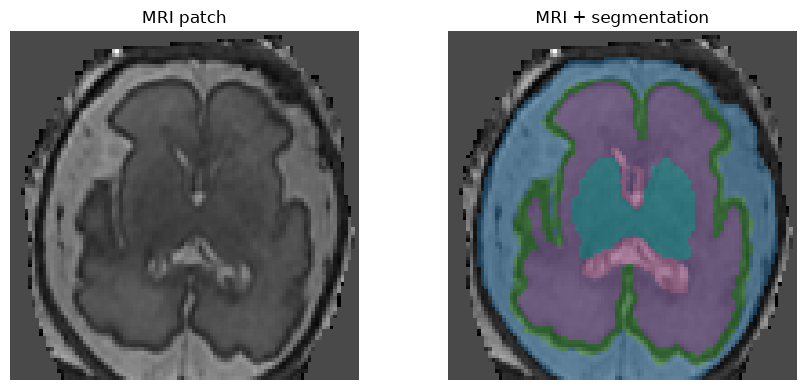

In [6]:

# Visualize one MRI patch and its segmentation overlay.
image = batch["image"][0, 0].numpy()
mask = batch["mask"][0].numpy()

z = image.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("MRI patch")

axes[1].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(mask[:, :, z].T == 0, mask[:, :, z].T),
    cmap="tab10",
    alpha=0.4,
    origin="lower",
    interpolation="nearest",
)
axes[1].set_title("MRI + segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 5. BOBs — Check a training patch

BOBs has several MRI sessions for some infants. We load one training session and check its patch size and labels.

In [7]:

bobs_train = BrainMRIPatchDataset(
    data_dir=BOBS_DIR,
    splits_path=SPLITS_DIR / "bobs_splits.json",
    dataset="bobs",
    split="train",
    patch_size=(96, 96, 96),
)

bobs_sample = bobs_train[0]

print("Number of BOBs training sessions:", len(bobs_train))
print("MRI patch:", bobs_sample["image"].shape)
print("Mask patch:", bobs_sample["mask"].shape)
print("Labels:", torch.unique(bobs_sample["mask"]).tolist())
print("Subject:", bobs_sample["subject"])
print("Session:", bobs_sample["session"])


Number of BOBs training sessions: 29
MRI patch: torch.Size([1, 96, 96, 96])
Mask patch: torch.Size([96, 96, 96])
Labels: [0, 1, 2, 3, 4, 5, 6, 7]
Subject: sub-116845
Session: ses-3mo


### BOBs — Random patch

Training patches are sampled randomly, so a patch can show only part of the brain.

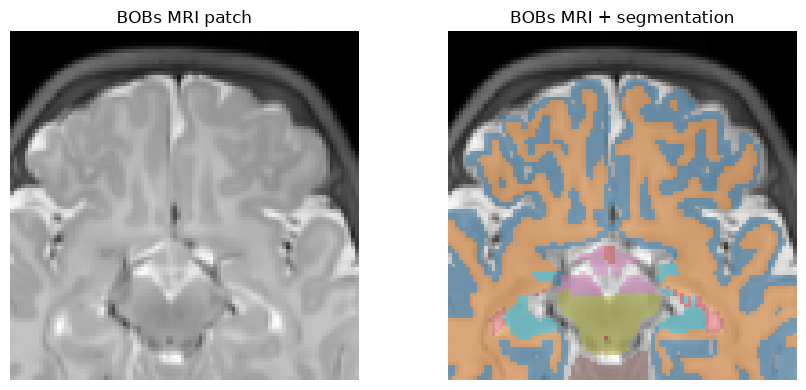

In [8]:

# Visualize a BOBs MRI patch and its segmentation.
image = bobs_sample["image"][0].numpy()
mask = bobs_sample["mask"].numpy()

z = image.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("BOBs MRI patch")

axes[1].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(mask[:, :, z].T == 0, mask[:, :, z].T),
    cmap="tab10",
    alpha=0.4,
    origin="lower",
    interpolation="nearest",
)
axes[1].set_title("BOBs MRI + segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### BOBs — Centered patch

For a clearer visual check, we also look at a centered validation patch. The mask seems to follow the MRI on this slice.

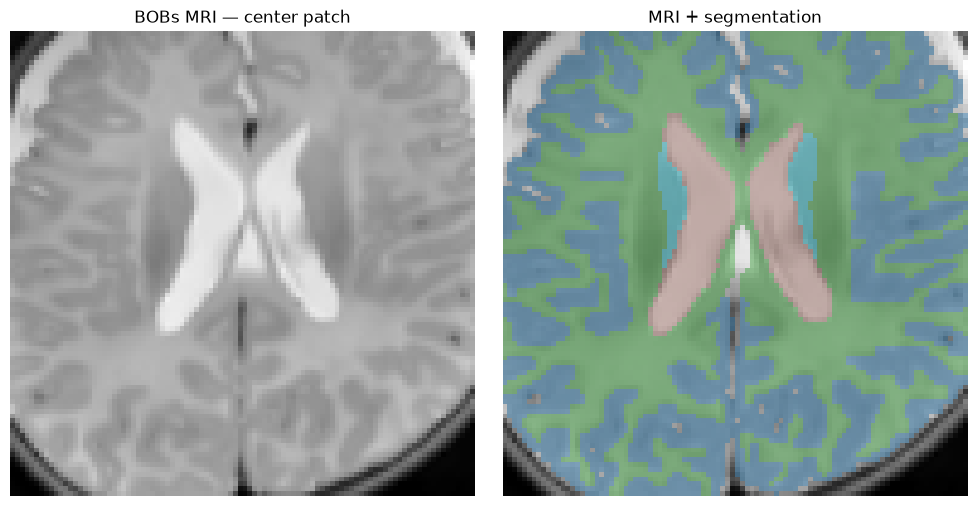

Subject: sub-684448
Session: ses-2mo


In [9]:

# Use a centered validation patch for a clearer visual check.
bobs_val = BrainMRIPatchDataset(
    data_dir=BOBS_DIR,
    splits_path=SPLITS_DIR / "bobs_splits.json",
    dataset="bobs",
    split="val",
    patch_size=(96, 96, 96),
)

sample = bobs_val[0]
image = sample["image"][0].numpy()
mask = sample["mask"].numpy()

z = image.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title("BOBs MRI — center patch")

axes[1].imshow(image[:, :, z].T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(mask[:, :, z].T == 0, mask[:, :, z].T),
    cmap="tab10",
    alpha=0.4,
    origin="lower",
    interpolation="nearest",
)
axes[1].set_title("MRI + segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Subject:", sample["subject"])
print("Session:", sample["session"])


## 6. BOBs — Test a batch

Finally, we check that the DataLoader can return two BOBs MRI patches and matching masks, with the expected shapes and label values.

In [11]:

from torch.utils.data import DataLoader

# Create the BOBs training DataLoader.
bobs_loader = DataLoader(
    bobs_train,
    batch_size=2,
    shuffle=True,
    num_workers=0,
)

batch_bobs = next(iter(bobs_loader))

print("Number of training sessions:", len(bobs_train))
print("MRI batch:", batch_bobs["image"].shape)
print("Mask batch:", batch_bobs["mask"].shape)
print("Subjects:", batch_bobs["subject"])
print("Sessions:", batch_bobs["session"])

# Check patch dimensions, types and labels.
assert batch_bobs["image"].shape == (2, 1, 96, 96, 96)
assert batch_bobs["mask"].shape == (2, 96, 96, 96)

assert batch_bobs["image"].dtype == torch.float32
assert batch_bobs["mask"].dtype == torch.int64

assert torch.isfinite(batch_bobs["image"]).all()

expected_labels = set(range(8))
labels = set(torch.unique(batch_bobs["mask"]).tolist())

assert labels.issubset(expected_labels)

print("All checks passed!")


Number of training sessions: 29
MRI batch: torch.Size([2, 1, 96, 96, 96])
Mask batch: torch.Size([2, 96, 96, 96])
Subjects: ['sub-981854', 'sub-116845']
Sessions: ['ses-1mo', 'ses-6mo']
All checks passed!
